# Segmentación de *Arabidopsis thaliana* con RGB: umbral manual, Otsu y Naive Bayes
**Big Data y Bioinformática · Google Colab**

**Pregunta:** ¿cómo cambia la calidad de segmentación entre tres métodos basados en canales RGB y qué tanto se mantienen sus resultados en otras accesiones?



## Bloque 1 · Librerías y descarga
Descarga el dataset directamente desde Kaggle.

In [9]:
# Instalar KaggleHub en Google Colab
!pip -q install kagglehub openpyxl

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from skimage import io, filters, morphology, measure
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import precision_score, recall_score, jaccard_score, confusion_matrix, ConfusionMatrixDisplay
import kagglehub

ruta_descarga = Path(kagglehub.dataset_download("shengyou222/plantgrowthsegmentationdataset"))
ruta = ruta_descarga / "train"
assert ruta.exists(), "No se encontró la carpeta train"
print("Dataset encontrado:", ruta)

Using Colab cache for faster access to the 'plantgrowthsegmentationdataset' dataset.
Dataset encontrado: /kaggle/input/plantgrowthsegmentationdataset/train


## Bloque 2 · Elegir C24 y comprobar los pares
Usaremos una sola carpeta durante el desarrollo. La correspondencia imagen-máscara se verifica por nombre.

In [10]:
# Carpeta de trabajo
accesion = "C24"
replica = "rep_01"
carpeta = ruta / accesion / replica

# Registrar los archivos que tienen una máscara con el mismo nombre
registros = []
for archivo in sorted((carpeta / "PNGImages").glob("*.png")):
    mascara = carpeta / "SegmentationClass" / archivo.name
    if mascara.exists():
        registros.append({"Accesion": accesion, "Replica": replica,
                          "Imagen": str(archivo), "Mascara": str(mascara),
                          "Archivo": archivo.name})

df_c24 = pd.DataFrame(registros)
assert len(df_c24) > 0, "No se encontraron imágenes emparejadas"
print("Pares imagen-máscara:", len(df_c24))
display(df_c24.head())
assert len(df_c24) == 55, "Revisar cantidad de archivos C24/rep_01 (versión del dataset distinta)"


Pares imagen-máscara: 55


,Accesion,Replica,Imagen,Mascara,Archivo
0,C24,rep_01,/kaggle/input/plantgrowthsegmentationdataset/t...,/kaggle/input/plantgrowthsegmentationdataset/t...,1000084_2022_05_11_12_09_35-2-171-TA03-RGB1_po...
1,C24,rep_01,/kaggle/input/plantgrowthsegmentationdataset/t...,/kaggle/input/plantgrowthsegmentationdataset/t...,1000084_2022_05_12_12_00_17-6-1-TA03-RGB1_pot_...
2,C24,rep_01,/kaggle/input/plantgrowthsegmentationdataset/t...,/kaggle/input/plantgrowthsegmentationdataset/t...,1000084_2022_05_12_15_00_17-6-2-TA03-RGB1_pot_...
3,C24,rep_01,/kaggle/input/plantgrowthsegmentationdataset/t...,/kaggle/input/plantgrowthsegmentationdataset/t...,1000084_2022_05_13_12_00_17-6-3-TA03-RGB1_pot_...
4,C24,rep_01,/kaggle/input/plantgrowthsegmentationdataset/t...,/kaggle/input/plantgrowthsegmentationdataset/t...,1000084_2022_05_13_15_00_16-6-4-TA03-RGB1_pot_...


## Bloque 3 · Revisar imagen, máscara y clases
La planta está rotulada como RGB `(250, 50, 83)`; el fondo, negro. Una etiqueta se crea **solo** a partir de las máscaras suministradas.

RGB: [0 0 0] | Píxeles: 269426
RGB: [250  50  83] | Píxeles: 4094


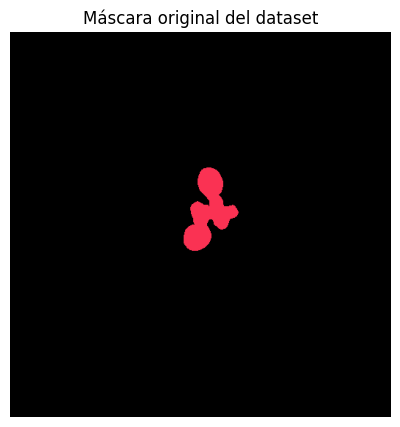

In [11]:
# ==========================================
# VERIFICAR COLORES DE LA MÁSCARA ORIGINAL
# ==========================================

# Seleccionar una máscara del dataset
fila = df_c24.iloc[0]
mascara = io.imread(fila["Mascara"])

# Obtener los colores RGB únicos y su frecuencia
colores, cantidades = np.unique(
    mascara[:, :, :3].reshape(-1, 3),
    axis=0,
    return_counts=True
)

# Mostrar los colores encontrados
for color, cantidad in zip(colores, cantidades):
    print(f"RGB: {color} | Píxeles: {cantidad}")

# Visualizar la máscara original
plt.figure(figsize=(5, 5))
plt.imshow(mascara)
plt.title("Máscara original del dataset")
plt.axis("off")
plt.show()


RGB: (526, 520, 3) uint8
Planta (píxeles): 74522


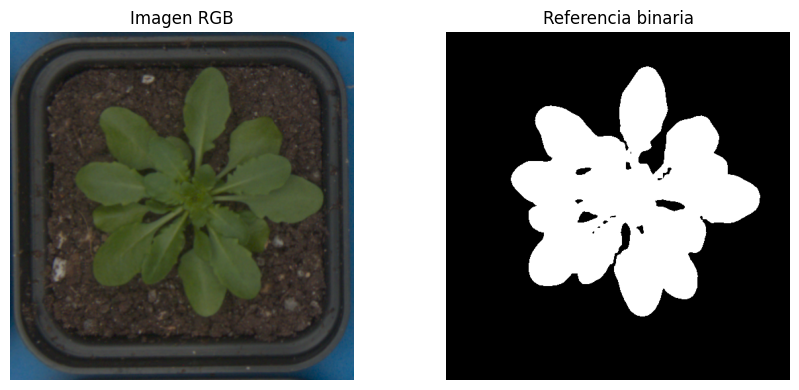

In [12]:
# Función para leer un par y convertir la máscara a clase binaria
COLOR_PLANTA = np.array([250, 50, 83])

def leer_par(fila):
    imagen = io.imread(fila["Imagen"])[..., :3]
    mascara = io.imread(fila["Mascara"])[..., :3]
    assert imagen.shape[:2] == mascara.shape[:2], "Dimensiones distintas"
    referencia = np.all(mascara == COLOR_PLANTA, axis=2)
    return imagen, referencia

fila = df_c24.iloc[len(df_c24)//2]
imagen, referencia = leer_par(fila)
print("RGB:", imagen.shape, imagen.dtype)
print("Planta (píxeles):", int(referencia.sum()))
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(imagen); ax[0].set_title("Imagen RGB")
ax[1].imshow(referencia, cmap="gray"); ax[1].set_title("Referencia binaria")
for eje in ax: eje.axis("off")
plt.tight_layout(); plt.show()

## Bloque 4 · Separar desarrollo y prueba interna
Se ordenan los nombres de archivo (incluyen marcas de fecha) y se reservan las últimas imágenes. No se mezclan píxeles de una fotografía entre entrenamiento y prueba. Son imágenes de una misma secuencia, por lo que esta es una prueba temporal interna, no una validación biológica independiente. texto en negrita texto en negrita

In [13]:
# Primeras ~70 % de las fotografías: desarrollo; restantes: prueba interna
# Orden lexicográfico de los nombres: revisar que respete las fechas
ordenado = df_c24.sort_values("Archivo").reset_index(drop=True)
corte = int(len(ordenado) * 0.70)
df_desarrollo = ordenado.iloc[:corte].copy()
df_prueba = ordenado.iloc[corte:].copy()
print("Desarrollo:", len(df_desarrollo), "| Prueba interna:", len(df_prueba))
print("Primer archivo:", ordenado.iloc[0]["Archivo"])
print("Último archivo:", ordenado.iloc[-1]["Archivo"])

Desarrollo: 38 | Prueba interna: 17
Primer archivo: 1000084_2022_05_11_12_09_35-2-171-TA03-RGB1_pot_C2_C24-01.png
Último archivo: 1000084_2022_06_07_15_00_17-6-54-TA03-RGB1_pot_C2_C24-01.png


## Bloque 5 · Histogramas de los canales R, G y B
Muestra una imagen inicial, intermedia y final del conjunto de desarrollo. Los histogramas de planta/fondo permiten justificar los límites manuales; se obtienen de las máscaras de referencia solo para explorar, no durante la predicción.

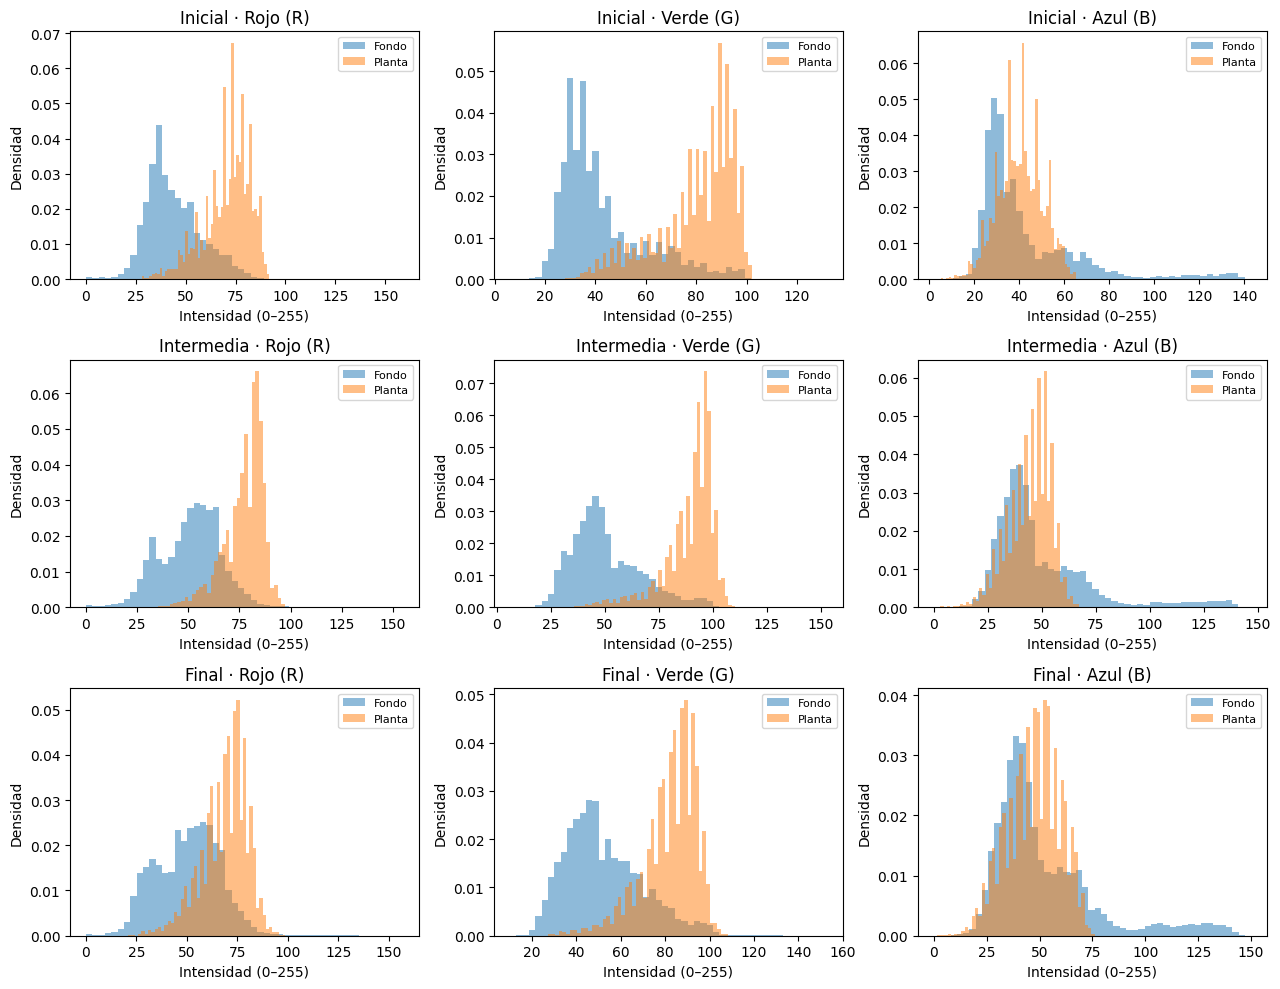

In [14]:
# Comparar distribución de planta y fondo por canal RGB
posiciones = [0, len(df_desarrollo)//2, len(df_desarrollo)-1]
etapas = ["Inicial", "Intermedia", "Final"]
fig, ax = plt.subplots(3, 3, figsize=(13, 10))
for i, posicion in enumerate(posiciones):
    imagen, referencia = leer_par(df_desarrollo.iloc[posicion])
    for canal, nombre in enumerate(["Rojo (R)", "Verde (G)", "Azul (B)"]):
        ax[i, canal].hist(imagen[..., canal][~referencia], bins=50,
                          density=True, alpha=0.5, label="Fondo")
        ax[i, canal].hist(imagen[..., canal][referencia], bins=50,
                          density=True, alpha=0.5, label="Planta")
        ax[i, canal].set_title(f"{etapas[i]} · {nombre}")
        ax[i, canal].set_xlabel("Intensidad (0–255)")
        ax[i, canal].set_ylabel("Densidad")
        ax[i, canal].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Bloque 6 · Umbralización manual RGB


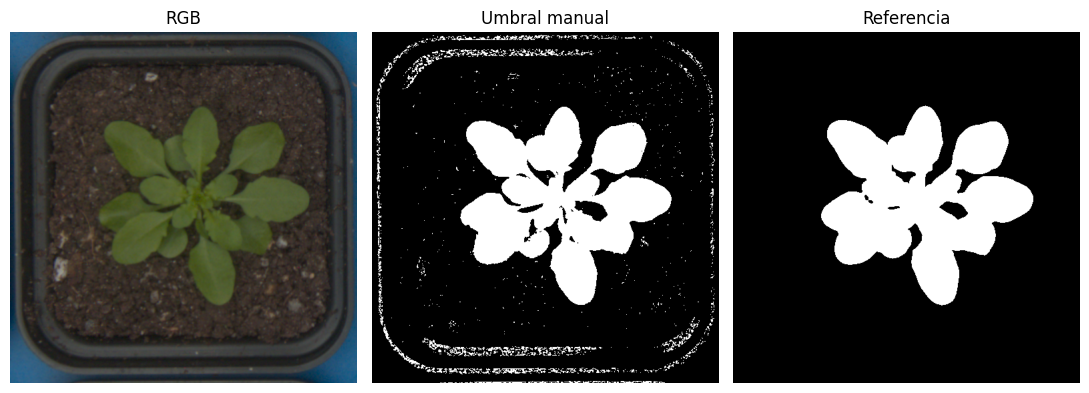

In [15]:
# Umbral RGB elegido manualmente tras observar histogramas
UMBRAL_G = 68

def segmentar_manual(imagen):
    R = imagen[..., 0].astype(float)
    G = imagen[..., 1].astype(float)
    B = imagen[..., 2].astype(float)
    return (G >= UMBRAL_G) & (G > R) & (G > B)

# Mostrar la segmentación manual de un ejemplo de desarrollo
imagen, referencia = leer_par(df_desarrollo.iloc[len(df_desarrollo)//2])
manual = segmentar_manual(imagen)
fig, ax = plt.subplots(1, 3, figsize=(11, 4))
for eje, im, titulo in zip(ax, [imagen, manual, referencia],
                           ["RGB", "Umbral manual", "Referencia"]):
    eje.imshow(im, cmap=None if titulo=="RGB" else "gray")
    eje.set_title(titulo); eje.axis("off")
plt.tight_layout(); plt.show()

## Bloque 7 · Otsu sobre el canal verde (G)
El umbral se calcula automáticamente solo con los píxeles donde G supera a R y B, y se aplica dentro de esa misma condición. La figura muestra el histograma del canal G de la imagen completa para contexto; la línea corresponde al umbral calculado sobre el subconjunto de verde predominante.

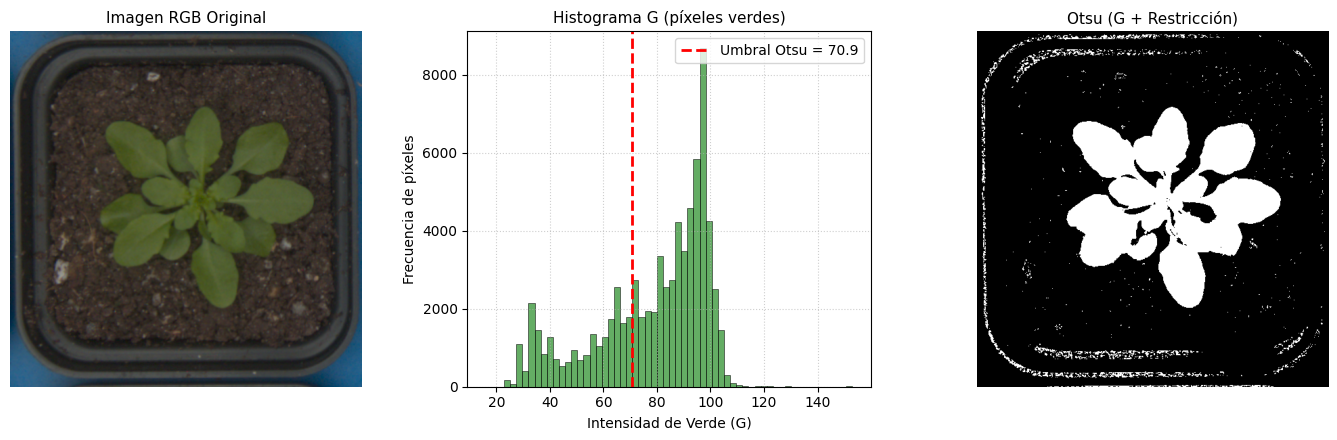

In [16]:
def segmentar_otsu(imagen):
    # Convertir a punto flotante para evitar desbordamientos
    R = imagen[..., 0].astype(float)
    G = imagen[..., 1].astype(float)
    B = imagen[..., 2].astype(float)

    # Mascara condicional para aislar el color verde dominante
    mascara_verde_predominante = (G > R) & (G > B)

    # Filtrar intensidades del canal G en los píxeles candidatos
    valores_verdes = G[mascara_verde_predominante]

    if len(valores_verdes) > 0:
        umbral = filters.threshold_otsu(valores_verdes)
    else:
        # Fallback en caso de que no haya píxeles que cumplan la condición
        umbral = filters.threshold_otsu(G)

    # Aplicar el umbral condicionado
    mascara_otsu = (G > umbral) & mascara_verde_predominante
    return mascara_otsu, umbral

# Probar la función con una imagen de desarrollo
imagen, referencia = leer_par(df_desarrollo.iloc[len(df_desarrollo)//2])
otsu, umbral_otsu = segmentar_otsu(imagen)

# Preparar visualización enriquecida
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))

# 1. Imagen RGB Original
ax[0].imshow(imagen)
ax[0].set_title("Imagen RGB Original", fontsize=11)
ax[0].axis("off")

# 2. Histograma del Canal Verde Predominante
R, G, B = [imagen[..., i].astype(float) for i in range(3)]
verdes = (G > R) & (G > B)
valores_histograma = G[verdes].ravel() if verdes.any() else G.ravel()

ax[1].hist(valores_histograma, bins=60, color='forestgreen', alpha=0.7, edgecolor='black', linewidth=0.5)
ax[1].axvline(umbral_otsu, color="red", linestyle="--", linewidth=2, label=f"Umbral Otsu = {umbral_otsu:.1f}")
ax[1].set_title("Histograma G (píxeles verdes)", fontsize=11)
ax[1].set_xlabel("Intensidad de Verde (G)")
ax[1].set_ylabel("Frecuencia de píxeles")
ax[1].legend(loc="upper right")
ax[1].grid(True, linestyle=":", alpha=0.6)

# 3. Resultado de la Segmentación Otsu
ax[2].imshow(otsu, cmap="gray")
ax[2].set_title("Otsu (G + Restricción)", fontsize=11)
ax[2].axis("off")

plt.tight_layout()
plt.show()

## Bloque 8 · Limpiezas morfológicas por método
La segmentación manual, Otsu y Naive Bayes pueden producir ruido distinto. Por eso se definen tres funciones.

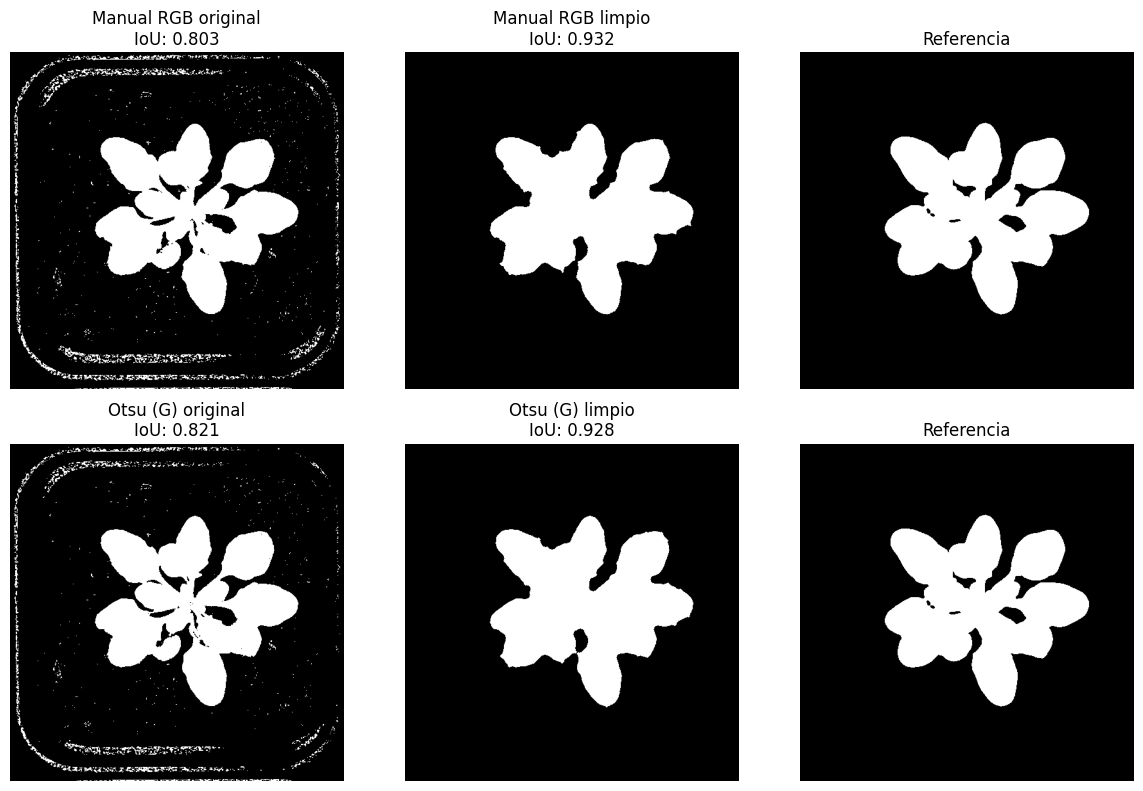

In [17]:
# ==========================================
# 1. FUNCIÓN PARA IDENTIFICAR LA PLANTA
# ==========================================

def seleccionar_planta(mascara):

    # Identificar componentes conectados
    etiquetas = measure.label(mascara)

    # Si no hay objetos, devolver máscara vacía
    if etiquetas.max() == 0:
        return mascara

    alto, ancho = mascara.shape

    # Centro de la imagen
    centro_y = alto / 2
    centro_x = ancho / 2

    # Evaluar los componentes identificados
    mejor_region = None
    mejor_puntuacion = -1

    for region in measure.regionprops(etiquetas):

        # Descartar componentes muy pequeños
        if region.area < 50:
            continue

        # Calcular distancia del centroide al centro
        y, x = region.centroid

        distancia = np.sqrt(
            ((y - centro_y) / alto)**2 +
            ((x - centro_x) / ancho)**2
        )

        # Priorizar regiones grandes y centrales
        puntuacion = region.area / (1 + 10 * distancia)

        if puntuacion > mejor_puntuacion:
            mejor_puntuacion = puntuacion
            mejor_region = region

    if mejor_region is None:
        return np.zeros_like(mascara, dtype=bool)

    return etiquetas == mejor_region.label


# ==========================================
# 2. LIMPIEZA DE SEGMENTACIÓN MANUAL
# ==========================================

def limpiar_manual(mascara):

    # Convertir a binaria
    binaria = mascara.astype(bool)

    # Cerrar discontinuidades pequeñas entre hojas
    limpia = morphology.closing(
        binaria, morphology.disk(5)
    )

    # Eliminar ruido fino
    limpia = morphology.opening(
        limpia, morphology.disk(1)
    )

    # Eliminar componentes pequeños
    limpia = morphology.remove_small_objects(
        limpia, min_size=100
    )

    # Seleccionar el componente principal
    limpia = seleccionar_planta(limpia)

    # Rellenar huecos interiores pequeños
    limpia = morphology.remove_small_holes(
        limpia, area_threshold=2000
    )

    return limpia


# ==========================================
# 3. LIMPIEZA DE SEGMENTACIÓN OTSU
# ==========================================

def limpiar_otsu(mascara):

    # Convertir a binaria
    binaria = mascara.astype(bool)

    # Cierre para unir discontinuidades
    limpia = morphology.closing(
        binaria, morphology.disk(6)
    )

    # Apertura para eliminar ruido fino
    limpia = morphology.opening(
        limpia, morphology.disk(2)
    )

    # Eliminar componentes pequeños
    limpia = morphology.remove_small_objects(
        limpia, min_size=100
    )

    # Seleccionar componente principal
    limpia = seleccionar_planta(limpia)

    # Rellenar huecos interiores
    limpia = morphology.remove_small_holes(
        limpia, area_threshold=2000
    )
    # Eliminar posibles bordes de la maceta
    alto, ancho = limpia.shape

    margen_y = int(alto * 0.08)
    margen_x = int(ancho * 0.08)

    limpia[:margen_y, :] = False
    limpia[alto-margen_y:, :] = False
    limpia[:, :margen_x] = False
    limpia[:, ancho-margen_x:] = False

    return limpia

# ==========================================
# 4. LIMPIEZA DE NAIVE BAYES
# ==========================================

def limpiar_bayes(mascara):
    # Tratamiento propio de Bayes: cierre moderado y selección central
    limpia = morphology.closing(mascara.astype(bool), morphology.disk(4))
    limpia = morphology.remove_small_objects(limpia, min_size=80)
    limpia = seleccionar_planta(limpia)
    limpia = morphology.remove_small_holes(limpia, area_threshold=1500)
    return limpia

# ==========================================
# 5. PROBAR LAS LIMPIEZAS
# ==========================================

# Seleccionar imagen central de desarrollo
fila = df_desarrollo.iloc[len(df_desarrollo)//2]

# Leer fotografía y máscara de referencia
imagen, referencia = leer_par(fila)

# Aplicar segmentaciones originales
manual_original = segmentar_manual(imagen)
otsu_original, _ = segmentar_otsu(imagen)

# Aplicar limpiezas
manual_limpio = limpiar_manual(manual_original)
otsu_limpio = limpiar_otsu(otsu_original)


# ==========================================
# 6. COMPARACIÓN VISUAL Y MÉTRICAS
# ==========================================

from sklearn.metrics import jaccard_score

fig, ax = plt.subplots(2, 3, figsize=(12, 8))

resultados = [
    (manual_original, manual_limpio, "Manual RGB"),
    (otsu_original, otsu_limpio, "Otsu (G)")
]

for i, (original, limpia, metodo) in enumerate(resultados):

    # Calcular IoU antes y después de limpiar
    iou_original = jaccard_score(
        referencia.ravel(),
        original.ravel(),
        zero_division=0
    )

    iou_limpio = jaccard_score(
        referencia.ravel(),
        limpia.ravel(),
        zero_division=0
    )

    # Mostrar máscara original
    ax[i, 0].imshow(original, cmap="gray")
    ax[i, 0].set_title(
        f"{metodo} original\nIoU: {iou_original:.3f}"
    )

    # Mostrar máscara limpia
    ax[i, 1].imshow(limpia, cmap="gray")
    ax[i, 1].set_title(
        f"{metodo} limpio\nIoU: {iou_limpio:.3f}"
    )

    # Mostrar referencia
    ax[i, 2].imshow(referencia, cmap="gray")
    ax[i, 2].set_title("Referencia")

    for j in range(3):
        ax[i, j].axis("off")

plt.tight_layout()
plt.show()


## Bloque 9 · Naive Bayes supervisado con RGB (como en clase)
Se toman píxeles etiquetados mediante máscaras de fotografías de desarrollo. El modelo `GaussianNB` aprende con columnas R, G, B y la clase binaria 0/1. Muestreamos hasta 300 píxeles por clase y fotografía para evitar millones de filas en memoria.

In [18]:
# ==========================================
# BLOQUE 9 - ENTRENAMIENTO NAIVE BAYES (RGB)
# ==========================================
from sklearn.naive_bayes import GaussianNB

rng = np.random.default_rng(42)
X_datos, y_datos = [], []

# Muestrear píxeles de ambas clases en cada imagen de desarrollo
for _, fila in df_desarrollo.iterrows():
    imagen, referencia = leer_par(fila)
    rgb = imagen[..., :3].astype(np.float32) / 255.0
    X = rgb.reshape(-1, 3)
    y = referencia.astype(np.uint8).ravel()
    for clase in [0, 1]:
        indices = np.flatnonzero(y == clase)
        if len(indices) == 0:
            continue
        seleccion = rng.choice(indices, size=min(500, len(indices)), replace=False)
        X_datos.append(X[seleccion]); y_datos.append(y[seleccion])

X_train = np.vstack(X_datos)
y_train = np.concatenate(y_datos)
assert set(np.unique(y_train)) == {0, 1}, "Se necesitan ejemplos de planta y fondo"
modelo_nb = GaussianNB()
modelo_nb.fit(X_train, y_train)

def segmentar_naive_bayes(imagen):
    # La misma escala [0,1] usada durante el entrenamiento
    rgb = imagen[..., :3].astype(np.float32) / 255.0
    X = rgb.reshape(-1, 3)
    return modelo_nb.predict(X).reshape(rgb.shape[:2]).astype(bool)

print("Píxeles de entrenamiento:", len(y_train))
print("Conteo por clase:", np.bincount(y_train))
print("Clases del modelo:", modelo_nb.classes_)


Píxeles de entrenamiento: 38000
Conteo por clase: [19000 19000]
Clases del modelo: [0 1]


## Bloque 10 · Visualización comparativa en una imagen de prueba


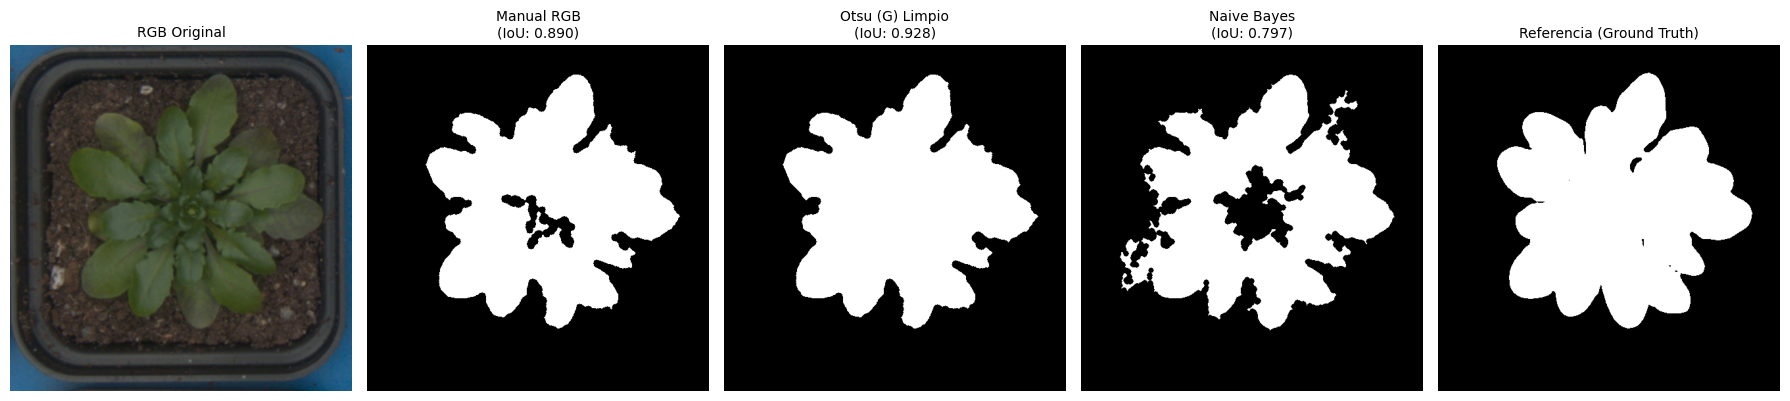

In [19]:
from sklearn.metrics import jaccard_score

fila = df_prueba.iloc[len(df_prueba)//2]
imagen, referencia = leer_par(fila)

# Obtener las predicciones aplicando sus respectivas limpiezas
manual = limpiar_manual(segmentar_manual(imagen))
otsu = limpiar_otsu(segmentar_otsu(imagen)[0])
nb = limpiar_bayes(segmentar_naive_bayes(imagen))

# Calcular métricas IoU para comparar numéricamente
iou_manual = jaccard_score(referencia.ravel(), manual.ravel(), zero_division=0)
iou_otsu = jaccard_score(referencia.ravel(), otsu.ravel(), zero_division=0)
iou_nb = jaccard_score(referencia.ravel(), nb.ravel(), zero_division=0)

# Mostrar resultados con títulos enriquecidos
fig, ax = plt.subplots(1, 5, figsize=(18, 4.5))
imagenes = [imagen, manual, otsu, nb, referencia]
titulos = [
    "RGB Original",
    f"Manual RGB\n(IoU: {iou_manual:.3f})",
    f"Otsu (G) Limpio\n(IoU: {iou_otsu:.3f})",
    f"Naive Bayes\n(IoU: {iou_nb:.3f})",
    "Referencia (Ground Truth)"
]

for eje, im, titulo in zip(ax, imagenes, titulos):
    eje.imshow(im, cmap=None if im.ndim == 3 else "gray")
    eje.set_title(titulo, fontsize=10)
    eje.axis("off")

plt.tight_layout()
plt.show()

## Bloque 11 · Evaluación numérica
La precisión, recall e IoU comparan cada máscara estimada con las etiquetas originales. Calculamos también error porcentual de área proyectada en píxeles, no área física en cm².

In [20]:
def evaluar_tabla(tabla, conjunto):
    filas = []
    for _, fila in tabla.iterrows():
        imagen, referencia = leer_par(fila)
        predicciones = {
            "Manual RGB": limpiar_manual(segmentar_manual(imagen)),
            "Otsu (G)": limpiar_otsu(segmentar_otsu(imagen)[0]),
            "Naive Bayes": limpiar_bayes(segmentar_naive_bayes(imagen))
        }
        for metodo, pred in predicciones.items():
            area_ref = int(referencia.sum())
            area_pred = int(pred.sum())
            filas.append({
                "Conjunto": conjunto, "Accesion": fila["Accesion"],
                "Replica": fila["Replica"], "Archivo": fila["Archivo"],
                "Metodo": metodo,
                "Precision": precision_score(referencia.ravel(), pred.ravel(), zero_division=0),
                "Recall": recall_score(referencia.ravel(), pred.ravel(), zero_division=0),
                "IoU": jaccard_score(referencia.ravel(), pred.ravel(), zero_division=0),
                "Area_referencia_px": area_ref, "Area_estimada_px": area_pred,
                "Error_area_pct": 100*(area_pred-area_ref)/area_ref if area_ref else np.nan
            })
    return pd.DataFrame(filas)

# Comprobación en fotografías no utilizadas para entrenar el modelo
res_c24 = evaluar_tabla(df_prueba, "Prueba interna C24")
print("Imágenes de prueba:", len(df_prueba))
display(res_c24.groupby("Metodo")[["Precision", "Recall", "IoU", "Error_area_pct"]].mean().round(3))

Imágenes de prueba: 17


,Precision,Recall,IoU,Error_area_pct
Metodo,,,,
Manual RGB,0.991,0.908,0.900,-8.310
Naive Bayes,0.971,0.856,0.835,-11.814
Otsu (G),0.977,0.952,0.931,-2.560


## Bloque 12 · Probar en otras dos accesiones (sin reentrenar)
Se aplican los mismos umbrales, la misma limpieza y el modelo entrenado solo con C24. Usamos `Ba4-1/rep_01` y `Can-0/rep_01`. Esta es la prueba de transferencia entre accesiones.

In [21]:
# Seleccionar pares de las otras dos accesiones sin modificar parámetros
pruebas_otras = []
for nombre in ["Ba4-1", "Can-0"]:
    base = ruta / nombre / "rep_01"
    for archivo in sorted((base / "PNGImages").glob("*.png")):
        mascara = base / "SegmentationClass" / archivo.name
        if mascara.exists():
            pruebas_otras.append({"Accesion": nombre, "Replica": "rep_01",
                                  "Imagen": str(archivo), "Mascara": str(mascara),
                                  "Archivo": archivo.name})

df_otras = pd.DataFrame(pruebas_otras)
res_otras = evaluar_tabla(df_otras, "Otras accesiones")
res_todos = pd.concat([res_c24, res_otras], ignore_index=True)
print("Imágenes externas:", len(df_otras))
display(res_todos.groupby(["Accesion", "Metodo"])[["Precision", "Recall", "IoU"]].mean().round(3))

Imágenes externas: 106


Precision  Recall    IoU
Accesion Metodo                               
Ba4-1    Manual RGB       0.982   0.806  0.790
         Naive Bayes      0.986   0.853  0.841
         Otsu (G)         0.950   0.874  0.846
C24      Manual RGB       0.991   0.908  0.900
         Naive Bayes      0.971   0.856  0.835
         Otsu (G)         0.977   0.952  0.931
Can-0    Manual RGB       0.977   0.927  0.908
         Naive Bayes      0.953   0.937  0.895
         Otsu (G)         0.971   0.940  0.915

## Bloque 13 · Figuras y error de área
Un boxplot de IoU por accesión y un resumen de error absoluto porcentual. Un error porcentual alto puede deberse en parte a áreas de referencia pequeñas.

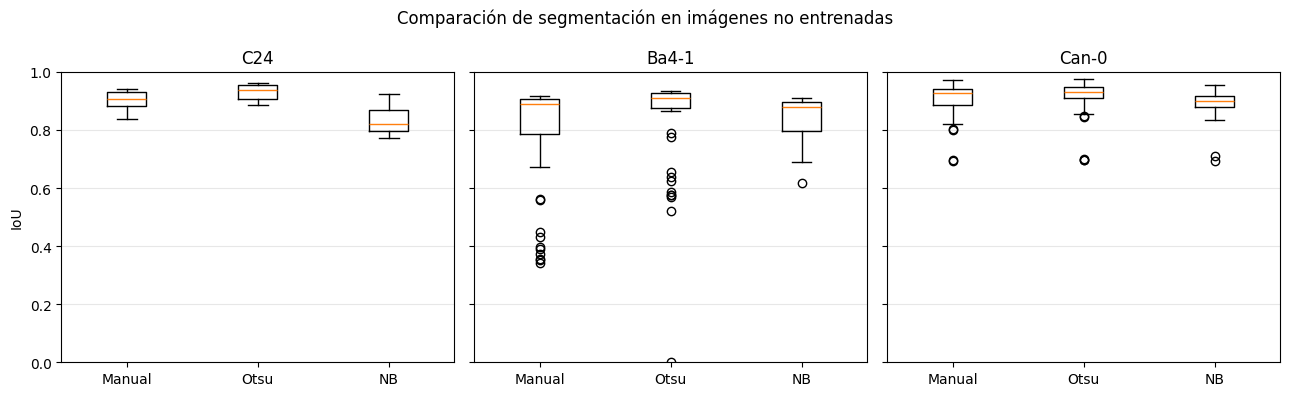

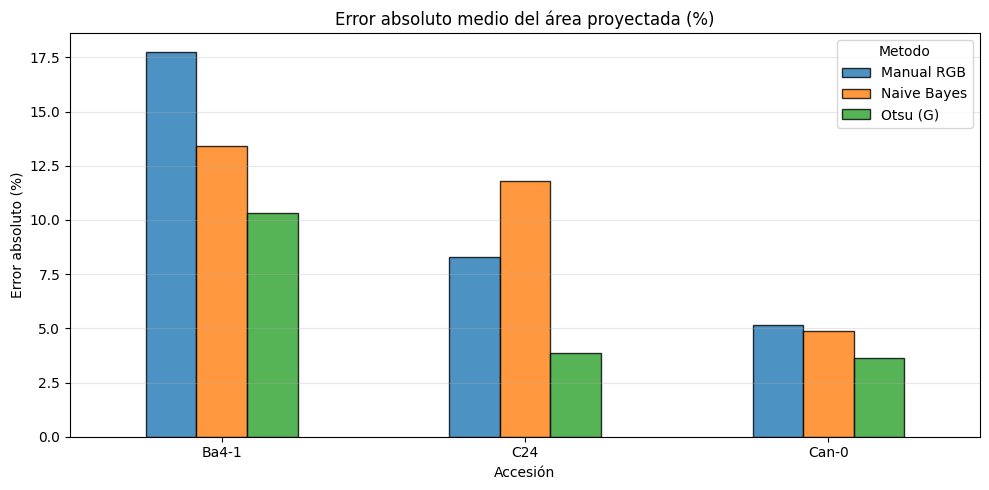

Error_area_pct  Error_absoluto_area_pct
Accesion Metodo                                              
Ba4-1    Manual RGB           -17.75                    17.75
         Naive Bayes          -13.43                    13.43
         Otsu (G)              -5.72                    10.34
C24      Manual RGB            -8.31                     8.31
         Naive Bayes          -11.81                    11.81
         Otsu (G)              -2.56                     3.87
Can-0    Manual RGB            -5.08                     5.14
         Naive Bayes           -1.45                     4.90
         Otsu (G)              -3.22                     3.62

In [22]:
# Boxplot: distribución de IoU, no solo su promedio
fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
metodos = ["Manual RGB", "Otsu (G)", "Naive Bayes"]
for i, nombre in enumerate(["C24", "Ba4-1", "Can-0"]):
    datos = res_todos[res_todos["Accesion"] == nombre]
    grupos = [datos.loc[datos["Metodo"] == m, "IoU"].dropna() for m in metodos]
    ax[i].boxplot(grupos, tick_labels=["Manual", "Otsu", "NB"])
    ax[i].set_title(nombre); ax[i].set_ylim(0, 1)
    ax[i].grid(axis="y", alpha=0.3)
ax[0].set_ylabel("IoU")
plt.suptitle("Comparación de segmentación en imágenes no entrenadas")
plt.tight_layout(); plt.show()

# Calcular error absoluto de área
res_todos["Error_absoluto_area_pct"] = res_todos["Error_area_pct"].abs()

# Gráfico de barras: error absoluto medio de área por accesión y método
resumen_errores = res_todos.groupby(["Accesion", "Metodo"])["Error_absoluto_area_pct"].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 5))
resumen_errores.plot(kind="bar", ax=ax, edgecolor="black", alpha=0.8)
ax.set_title("Error absoluto medio del área proyectada (%)")
ax.set_ylabel("Error absoluto (%)")
ax.set_xlabel("Accesión")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

# Mostrar tabla de resultados resumidos
display(res_todos.groupby(["Accesion", "Metodo"])[["Error_area_pct", "Error_absoluto_area_pct"]].mean().round(2))

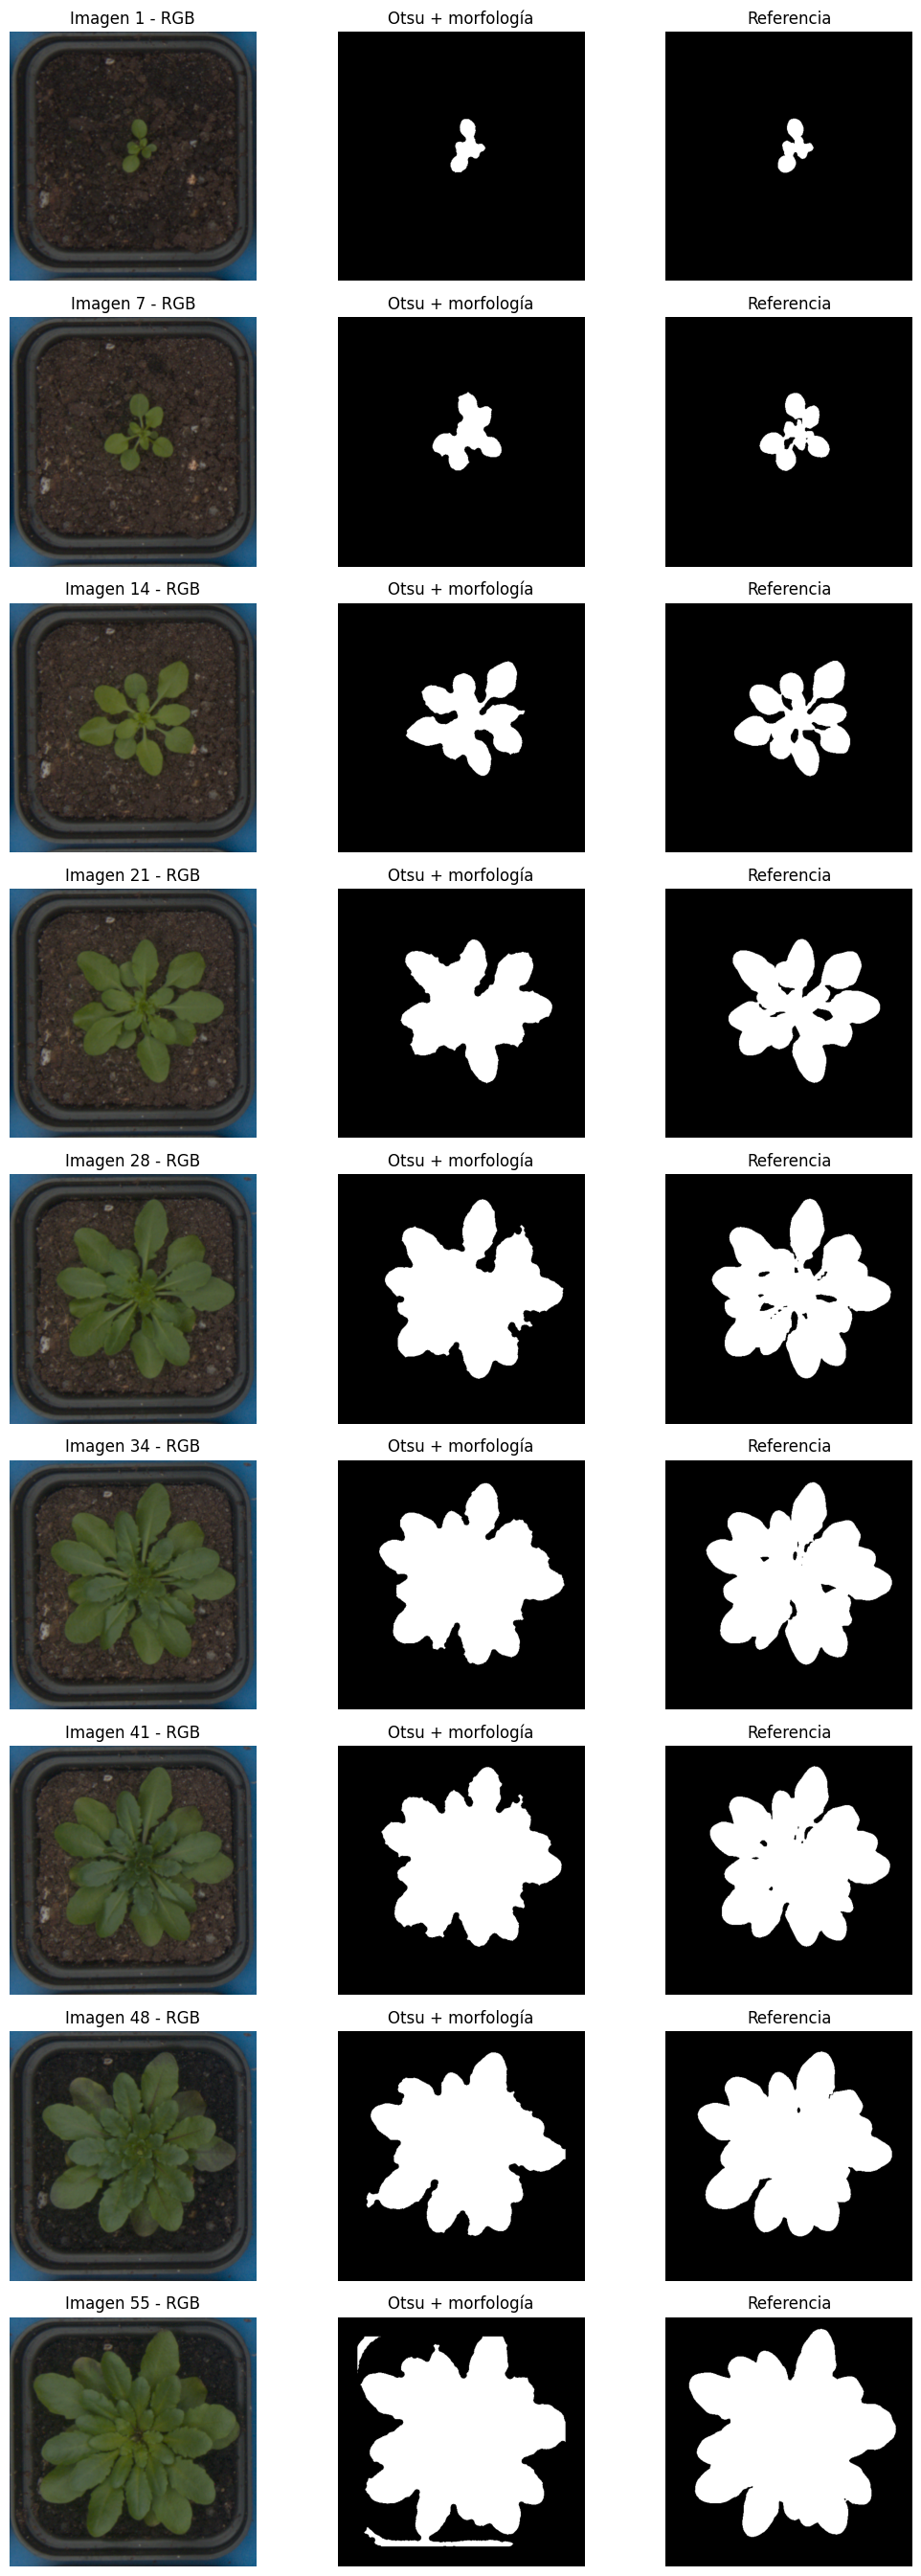

In [25]:

# ==========================================
# BLOQUE 15 - VISUALIZACIÓN DE 9 IMÁGENES
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# Ordenar las imágenes de C24 por nombre
datos = df_c24.sort_values("Imagen").reset_index(drop=True)

# Seleccionar 9 imágenes distribuidas en la secuencia
posiciones = np.linspace(0, len(datos)-1, 9, dtype=int)

# Crear figura de 9 filas y 3 columnas
fig, ax = plt.subplots(9, 3, figsize=(11, 27))

for i, posicion in enumerate(posiciones):

    # Leer imagen y máscara de referencia
    fila = datos.iloc[posicion]
    imagen, referencia = leer_par(fila)

    # Aplicar Otsu y su limpieza morfológica
    otsu_original, _ = segmentar_otsu(imagen)
    otsu_limpio = limpiar_otsu(otsu_original)

    # Mostrar fotografía RGB
    ax[i, 0].imshow(imagen)
    ax[i, 0].set_title(f"Imagen {posicion + 1} - RGB")

    # Mostrar segmentación final
    ax[i, 1].imshow(otsu_limpio, cmap="gray")
    ax[i, 1].set_title("Otsu + morfología")

    # Mostrar máscara original
    ax[i, 2].imshow(referencia, cmap="gray")
    ax[i, 2].set_title("Referencia")

    # Ocultar ejes
    for j in range(3):
        ax[i, j].axis("off")

plt.tight_layout()
plt.show()


## Bloque 16 · Comprobación final y registro de versiones
Verifica la integridad de los resultados y registra las versiones del software utilizado.

In [26]:
# Comprobar que las métricas incluyen todos los pares y los tres métodos
import sklearn, skimage, sys
assert len(df_desarrollo) == 38 and len(df_prueba) == 17
assert len(df_otras) == 106
assert len(res_c24) == 17 * 3 and len(res_otras) == 106 * 3
assert res_todos["IoU"].between(0, 1).all()
print("Validación de número de registros: correcta")
print("Python:", sys.version.split()[0])
print("scikit-image:", skimage.__version__)
print("scikit-learn:", sklearn.__version__)


Validación de número de registros: correcta
Python: 3.13.18
scikit-image: 0.25.2
scikit-learn: 1.6.1
